<a href="https://colab.research.google.com/github/ahnjj/AI/blob/master/Happiness_Estimation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1.   Question**

Started from general curiosity, "Which indicators are most strongly associated with / affect the level of nation's happiness?"
I defined the question of this project "How can socioeconomic indicators predict a country's happiness score in a later report year?"

# **2. Data**

**Data Source**

I will use the World Happiness Report dataset, sourced from Kaggle, covering the years 2015–2019. The data was originally from the Gallup World Poll. The scores are based on answers to the evaluation question asked in the poll.

**What do they describe?**

The dataset includes country-level happiness scores, rankings, and several socioeconomic indicators, such as GDP per capita, social support, life expectancy, freedom, generosity, and perceptions of corruption.

These indicators describe the extent to which these factors contribute in evaluating the happiness in each country.

**Value Range**


Target : Happiness Score(0~10)


Features :


**Is it primary or secondary**


Since I downloaded this dataset from Kaggle, this is secondary data.

**Any potential sources of bias**


Since I am using 5 years of datasets, each dataset file overlaps same countries. I assume even the slight change of features would affect "Happiness Score" neverthless they are the same country in another year. This is why I concatenated 5 years of data without dropping rows.
However, there is a possibility of data leakage - target leakage by giving hints of target value through the same country names.





---

# **3. Inspect each annual dataset**
Let's briefly see how the data looks like.

In [217]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Check Datasets
files = ["2015.csv", "2016.csv", "2017.csv", "2018.csv","2019.csv"]
for file in files:
    yearly_df = kagglehub.dataset_load(
        KaggleDatasetAdapter.PANDAS,
        "unsdsn/world-happiness",
        file,
    )

    print(f"\nFirst 5 rows of {file}:")
    display(yearly_df.head())
    print("Shape:", yearly_df.shape)

Using Colab cache for faster access to the 'world-happiness' dataset.

First 5 rows of 2015.csv:


,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Switzerland,Western Europe,1,7.587,0.03411,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2.51738
1,Iceland,Western Europe,2,7.561,0.04884,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2.70201
2,Denmark,Western Europe,3,7.527,0.03328,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2.49204
3,Norway,Western Europe,4,7.522,0.03880,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699,2.46531
4,Canada,North America,5,7.427,0.03553,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811,2.45176


Shape: (158, 12)
Using Colab cache for faster access to the 'world-happiness' dataset.

First 5 rows of 2016.csv:


,Country,Region,Happiness Rank,Happiness Score,Lower Confidence Interval,Upper Confidence Interval,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Denmark,Western Europe,1,7.526,7.460,7.592,1.44178,1.16374,0.79504,0.57941,0.44453,0.36171,2.73939
1,Switzerland,Western Europe,2,7.509,7.428,7.590,1.52733,1.14524,0.86303,0.58557,0.41203,0.28083,2.69463
2,Iceland,Western Europe,3,7.501,7.333,7.669,1.42666,1.18326,0.86733,0.56624,0.14975,0.47678,2.83137
3,Norway,Western Europe,4,7.498,7.421,7.575,1.57744,1.12690,0.79579,0.59609,0.35776,0.37895,2.66465
4,Finland,Western Europe,5,7.413,7.351,7.475,1.40598,1.13464,0.81091,0.57104,0.41004,0.25492,2.82596


Shape: (157, 13)
Using Colab cache for faster access to the 'world-happiness' dataset.

First 5 rows of 2017.csv:


,Country,Happiness.Rank,Happiness.Score,Whisker.high,Whisker.low,Economy..GDP.per.Capita.,Family,Health..Life.Expectancy.,Freedom,Generosity,Trust..Government.Corruption.,Dystopia.Residual
0,Norway,1,7.537,7.594445,7.479556,1.616463,1.533524,0.796667,0.635423,0.362012,0.315964,2.277027
1,Denmark,2,7.522,7.581728,7.462272,1.482383,1.551122,0.792566,0.626007,0.355280,0.400770,2.313707
2,Iceland,3,7.504,7.622030,7.385970,1.480633,1.610574,0.833552,0.627163,0.475540,0.153527,2.322715
3,Switzerland,4,7.494,7.561772,7.426227,1.564980,1.516912,0.858131,0.620071,0.290549,0.367007,2.276716
4,Finland,5,7.469,7.527542,7.410458,1.443572,1.540247,0.809158,0.617951,0.245483,0.382612,2.430182


Shape: (155, 12)
Using Colab cache for faster access to the 'world-happiness' dataset.

First 5 rows of 2018.csv:


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.632,1.305,1.592,0.874,0.681,0.202,0.393
1,2,Norway,7.594,1.456,1.582,0.861,0.686,0.286,0.340
2,3,Denmark,7.555,1.351,1.590,0.868,0.683,0.284,0.408
3,4,Iceland,7.495,1.343,1.644,0.914,0.677,0.353,0.138
4,5,Switzerland,7.487,1.420,1.549,0.927,0.660,0.256,0.357


Shape: (156, 9)
Using Colab cache for faster access to the 'world-happiness' dataset.

First 5 rows of 2019.csv:


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


Shape: (156, 9)


### What we can observe:

- Each years of dataset has 155~158 rows



- Different features with similar meaning : We need to **standardize feature names.**

- There are several features that don't seem to have direct relationships with happiness, but only are present in few years : We can **drop** those feature columns.


- This datasets are Panel data, which means that multiple entities(country) are repeated over time. *i.e. Many countries' happiness scores from 2015~2019.*



# Standardize Feature Names

**1. Country**
*   2018, 2019: "Country or region" → "Country"

**2. Happiness Rank**
*   2017: "Happiness.Rank" → "Happiness Rank"
*   2018, 2019: "Overall rank" → "Happiness Rank"

**3. Happiness Score**
*   2017: "Happiness.Score" → "Happiness Score"
*   2018, 2019: "Score" → "Happiness Score"

**4. Economy (GDP per Capita)**
*   2017: "Economy..GDP.per.Capita." → "Economy (GDP per Capita)"
*   2018, 2019: "GDP per capita" → "Economy (GDP per Capita)"

**5. Health (Life Expectancy)**
*   2017: "Health..Life.Expectancy." → "Health (Life Expectancy)"
*   2018, 2019: "Healthy life expectancy" → "Health (Life Expectancy)"

**6. Freedom**
*   2018, 2019: "Freedom to make life choices" → "Freedom"


**7. Trust (Government Corruption)**
*   2017: "Trust..Government.Corruption." → "Trust (Government Corruption)"
*   2018, 2019: "Perceptions of corruption" → "Trust (Government Corruption)"


**8. Social Support**
*   Since Family is one part of social support → "Social Support"



In [218]:
import pandas as pd

files = ["2015.csv", "2016.csv", "2017.csv", "2018.csv", "2019.csv"]

# Mapping Feature Names
column_mapping = {
    "Country or region": "Country",
    "Happiness.Rank": "Happiness Rank",
    "Overall rank": "Happiness Rank",
    "Happiness.Score": "Happiness Score",
    "Score": "Happiness Score",
    "Economy..GDP.per.Capita.": "Economy (GDP per Capita)",
    "GDP per capita": "Economy (GDP per Capita)",
    "Health..Life.Expectancy.": "Health (Life Expectancy)",
    "Healthy life expectancy": "Health (Life Expectancy)",
    "Freedom to make life choices": "Freedom",
    "Trust..Government.Corruption.": "Trust (Government Corruption)",
    "Perceptions of corruption": "Trust (Government Corruption)",
    "Family": "Social Support",
    "Social support": "Social Support",
}

# Drop Column
Drop columns that are only present in datasets from specific years.

1. **Standard Error of the Happiness Score** : only present in 2015



2. **Dystopia.Residual** : unavailable in 2018 and 2019 and its meaning is unclear, seems not giving quality information about happiness score estimation.

3. **Lower Confidence Interval, Upper Confidence Interval** : Only present in 2016

4. **Whisker.high, Whisker.low** : Only present in 2017

Drop column that would result in data leakage.

5. **Happiness Rank** : Since this is ordering by Happiness Score(Target), it could be target leakage by revealing information derived from the target.


In [219]:
# Drop columns that are unavailable across all five years or not giving necessary information
columns_to_drop = [
    "Standard Error",
    "Dystopia Residual",  # 2015, 2016
    "Dystopia.Residual",  # 2017
    "Lower Confidence Interval",
    "Upper Confidence Interval",
    "Whisker.high",
    "Whisker.low",
    "Happiness Rank",

]

In [220]:
# Conduct dropping and standarization
datasets = []

for file in files:
    yearly_df = kagglehub.dataset_load(
        KaggleDatasetAdapter.PANDAS,
        "unsdsn/world-happiness",
        file,
    )

    # Standardize column names
    yearly_df = yearly_df.rename(columns=column_mapping)

    # Add the year
    yearly_df["Year"] = int(file.split(".")[0])

    yearly_df = yearly_df.drop(columns=columns_to_drop, errors="ignore") # Drop columns

    # Display the first five rows of each file
    print(f"\nFirst 2 rows of {file}:")
    display(yearly_df.head(2))
    print("Shape:", yearly_df.shape)

    datasets.append(yearly_df) # Append in the list

Using Colab cache for faster access to the 'world-happiness' dataset.

First 2 rows of 2015.csv:


,Country,Region,Happiness Score,Economy (GDP per Capita),Social Support,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Year
0,Switzerland,Western Europe,7.587,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2015
1,Iceland,Western Europe,7.561,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2015


Shape: (158, 10)
Using Colab cache for faster access to the 'world-happiness' dataset.

First 2 rows of 2016.csv:


,Country,Region,Happiness Score,Economy (GDP per Capita),Social Support,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Year
0,Denmark,Western Europe,7.526,1.44178,1.16374,0.79504,0.57941,0.44453,0.36171,2016
1,Switzerland,Western Europe,7.509,1.52733,1.14524,0.86303,0.58557,0.41203,0.28083,2016


Shape: (157, 10)
Using Colab cache for faster access to the 'world-happiness' dataset.

First 2 rows of 2017.csv:


,Country,Happiness Score,Economy (GDP per Capita),Social Support,Health (Life Expectancy),Freedom,Generosity,Trust (Government Corruption),Year
0,Norway,7.537,1.616463,1.533524,0.796667,0.635423,0.362012,0.315964,2017
1,Denmark,7.522,1.482383,1.551122,0.792566,0.626007,0.355280,0.400770,2017


Shape: (155, 9)
Using Colab cache for faster access to the 'world-happiness' dataset.

First 2 rows of 2018.csv:


,Country,Happiness Score,Economy (GDP per Capita),Social Support,Health (Life Expectancy),Freedom,Generosity,Trust (Government Corruption),Year
0,Finland,7.632,1.305,1.592,0.874,0.681,0.202,0.393,2018
1,Norway,7.594,1.456,1.582,0.861,0.686,0.286,0.340,2018


Shape: (156, 9)
Using Colab cache for faster access to the 'world-happiness' dataset.

First 2 rows of 2019.csv:


,Country,Happiness Score,Economy (GDP per Capita),Social Support,Health (Life Expectancy),Freedom,Generosity,Trust (Government Corruption),Year
0,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393,2019
1,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410,2019


Shape: (156, 9)


Now all five annual datasets use consistent feature names.
However, the 2018 and 2019 datasets don't have 'region' column, we will  impute these missing values after the data split.


Again, here you can see the same country, such as "Finland", can have different Happiness Score and predictor values across different years. Therefore concatening the 5 annual datasets can create a panel dataset.






---
# **Concat Data**
Now we can concat 5 years of dataset into one dataset.

In [221]:
# Combine all five datasets
df = pd.concat(datasets, ignore_index=True)

display(df.head())
print("Combined shape:", df.shape)

,Country,Region,Happiness Score,Economy (GDP per Capita),Social Support,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Year
0,Switzerland,Western Europe,7.587,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2015
1,Iceland,Western Europe,7.561,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2015
2,Denmark,Western Europe,7.527,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2015
3,Norway,Western Europe,7.522,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699,2015
4,Canada,North America,7.427,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811,2015


Combined shape: (782, 10)


Combined datasets have 782 rows, and 10 features.

# Split Data


- Since this datasets is small (about 780 in total), and we are going to using only 60% for training.

- Also, we are going to conduct chronological split
  - a. since this is panel data,
  - b. our goal is to predict happiness in a later year.

This is how the split proportion looks:

| Dataset | Years | Percentage of years | Purpose |
|---|---|---:|---|
| Training | 2015–2017 | 60% | Fit the models |
| Validation | 2018 | 20% | Choose models and hyperparameters |
| Test | 2019 | 20% | Evaluate the model |






In [222]:
# Split Chronologically
train_df = df[df["Year"].between(2015, 2017).copy()]
val_df = df[df["Year"] == 2018].copy()
test_df = df[df["Year"] == 2019].copy()

# Display row counts and % of each split
split_summary = pd.DataFrame({
    "Dataset":["Training", "Validation", "Test"],
    "Years": ["2015-2017", "2018", "2019"],
    "Rows": [len(train_df), len(val_df), len(test_df)],
    "Percentage" : [ len(train_df) / len(df) * 100, len(val_df) / len(df) * 100 , len(test_df) / len(df) * 100]
})

display(split_summary)

,Dataset,Years,Rows,Percentage
0,Training,2015-2017,470,60.102302
1,Validation,2018,156,19.948849
2,Test,2019,156,19.948849


# **4.Curation**
*   Missingness - if any data is missing, quantify it and classify it as MCAR, MAR, or MNAR.
How do you handle it? For example, with removal or imputation.
*   Outliers - Do any unusual or extraneous datapoints exist? Find them and investigate them before training a model. Do not delete a point merely for being extreme; if you do remove any, you must justify it.


*   A leakage audit — Is there a risk of leakage for any of the features in your dataset? If so, how
do you split in such a way to mitigate the leakage between training, validation, and test sets?
*   Encoding and scaling — Explain any feature engineering and standardization you perform.




## **Missing Data**

#### 1. Visualize the data missingness

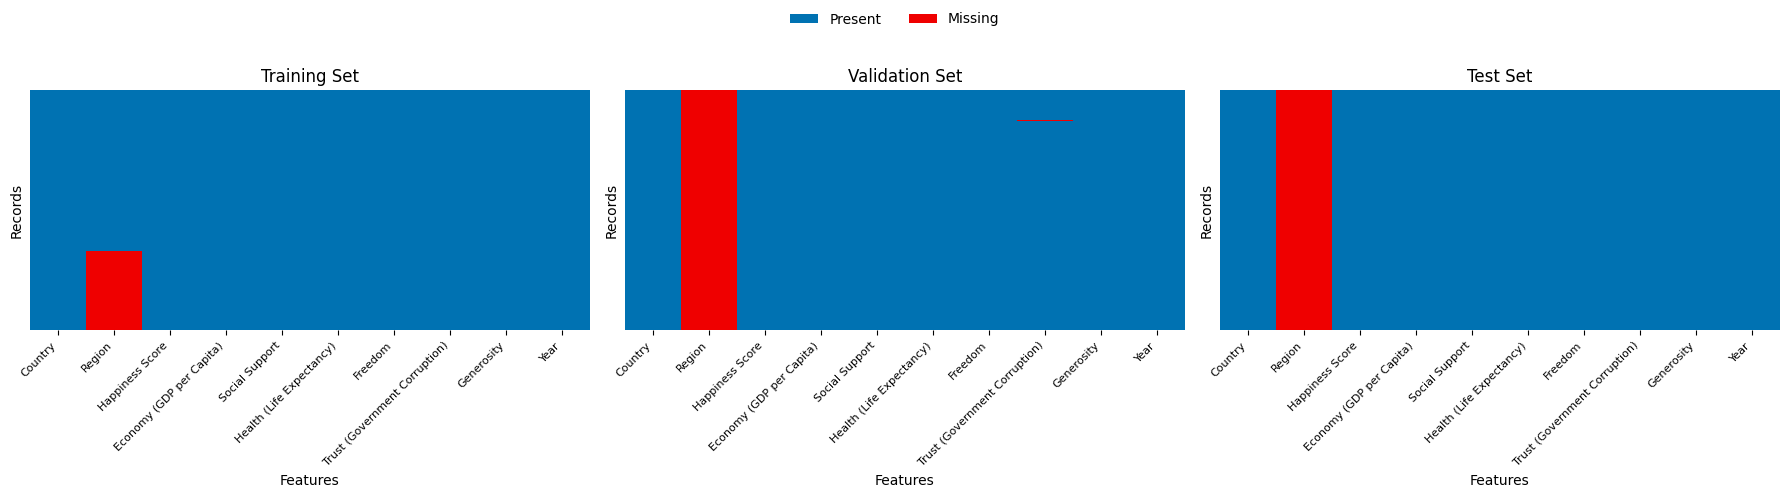

In [223]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, data) in zip(axes, [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]):
    sns.heatmap(
        data.isna(),
        cmap=ListedColormap(["#0072B2", "#EF0000"]),
        vmin=0,
        vmax=1,
        cbar=False,
        yticklabels=False,
        ax=ax
    )

    ax.set_title(f"{name} Set")
    ax.set_xlabel("Features")
    ax.set_ylabel("Records")
    ax.tick_params(axis="x", labelsize=8)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

# One shared legend
fig.legend(
    handles=[
        Patch(facecolor="#0072B2", label="Present"),
        Patch(facecolor="#EF0000", label="Missing"),
    ],
    loc="upper center",
    ncol=2,
    frameon=False
)

fig.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

#### 2. Quantify the missingness

In [224]:
# Browse Missing Data
def search_missing(data):
  return pd.DataFrame({
      "Missing Count" : data.isna().sum(),
      "Missing Ratio(%)" : (data.isna().mean() * 100).round(2),
  }).sort_values(by="Missing Count", ascending=False)

print("Training Data:")
display(search_missing(train_df))

print("\nValidation Data:")
display(search_missing(val_df))

print("\nTest Data:")
display(search_missing(test_df))

Training Data:


,Missing Count,Missing Ratio(%)
Region,155,32.98
Country,0,0.00
Happiness Score,0,0.00
Economy (GDP per Capita),0,0.00
Social Support,0,0.00
Health (Life Expectancy),0,0.00
Freedom,0,0.00
Trust (Government Corruption),0,0.00
Generosity,0,0.00
Year,0,0.00



Validation Data:


,Missing Count,Missing Ratio(%)
Region,156,100.00
Trust (Government Corruption),1,0.64
Country,0,0.00
Happiness Score,0,0.00
Social Support,0,0.00
Economy (GDP per Capita),0,0.00
Health (Life Expectancy),0,0.00
Freedom,0,0.00
Generosity,0,0.00
Year,0,0.00



Test Data:


,Missing Count,Missing Ratio(%)
Region,156,100.0
Country,0,0.0
Happiness Score,0,0.0
Economy (GDP per Capita),0,0.0
Social Support,0,0.0
Health (Life Expectancy),0,0.0
Freedom,0,0.0
Trust (Government Corruption),0,0.0
Generosity,0,0.0
Year,0,0.0


### Result of missingness analysis
| Feature | Missingness | Interpretation | Handling |
|---|---|---|---|
| Region | ~30% training; 100% validation/test | **MCAR** - Entire annual files lack this feature, however, it doesn't have specific reason for missing; **structural missingness** | Imputation: using training dataset's country-to-region values |
| Trust | 0.64% validation | The number alone can't establish **MCAR(e.g.forget to answer) or MNAR(e.g. fear of government)** | Since only one data is missing from validation set, impute this value with the median value of training set|






#### **1. Missing Data(Region) : Imputation**
- Here, some countries used different names across years. However, assume that we didn't know which countries use different names, we are going to make initial lookup.

In [225]:
# Create a Country → Region lookup using existing values

splits = [train_df, val_df, test_df]

# 1. Initial lookup
region_lookup = (
    pd.concat(splits)
    .dropna(subset=["Region"])
    .drop_duplicates("Country")
    .set_index("Country")["Region"]
)

# Fill and inspect unmatched countries
for data in splits:
    data["Region"] = data["Region"].fillna(data["Country"].map(region_lookup))
    print(data.loc[data["Region"].isna(), "Country"].unique())


['Taiwan Province of China' 'Hong Kong S.A.R., China']
['Trinidad & Tobago' 'Northern Cyprus']
['Trinidad & Tobago' 'Northern Cyprus' 'North Macedonia' 'Gambia']


/tmp/ipykernel_6275/3463485687.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["Region"] = data["Region"].fillna(data["Country"].map(region_lookup))


Some countries may use different names across years.


Standardize those names and then fill regions again!|

In [226]:
# Standardize country names across years
country_mapping = {
    "Taiwan Province of China": "Taiwan",
    "Hong Kong S.A.R., China": "Hong Kong",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "North Macedonia": "Macedonia",
    "Northern Cyprus" : "North Cyprus"
}

for data in splits:
    data["Country"] = data["Country"].replace(country_mapping)

# Rebuild the lookup after standardizing names
region_lookup = (
    pd.concat(splits)
    .dropna(subset=["Region"])
    .drop_duplicates("Country")
    .set_index("Country")["Region"]
)

# Fill again
for data in splits:
    data["Region"] = data["Region"].fillna(data["Country"].map(region_lookup))
    print(data.loc[data["Region"].isna(), "Country"].unique())  # Inspect again


[]
[]
['Gambia']


/tmp/ipykernel_6275/1123514929.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["Country"] = data["Country"].replace(country_mapping)
/tmp/ipykernel_6275/1123514929.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["Region"] = data["Region"].fillna(data["Country"].map(region_lookup))


Gambia only presents in 2019, which doesn't has 'region' feature.

Using domain knowledge(Googling), fill Gambia's region data.

In [227]:
mask = df["Country"].isin(["Gambia"]) & df["Region"].isna()
for data in splits:
  data.loc[mask, "Region"] = "Sub-Saharan Africa"


  # Double Check
  print(data.loc[data["Region"].isna(), "Country"].unique())

[]
[]
[]


#### **2. Missing Data (Trust) : Impute with the median data**

In [228]:
trust_col = "Trust (Government Corruption)"

# Calculate the training median
trust_median = train_df[trust_col].median()

# Fill missing values in validation split
val_df[trust_col] = val_df[trust_col].fillna(trust_median)

print(f"{val_df[trust_col].isna().sum()} missing Trust values") # Double Check

print("Median used:", trust_median)

0 missing Trust values
Median used: 0.09950173646211624


### Outliers

Visualize outliers with boxplots and scatterplots.



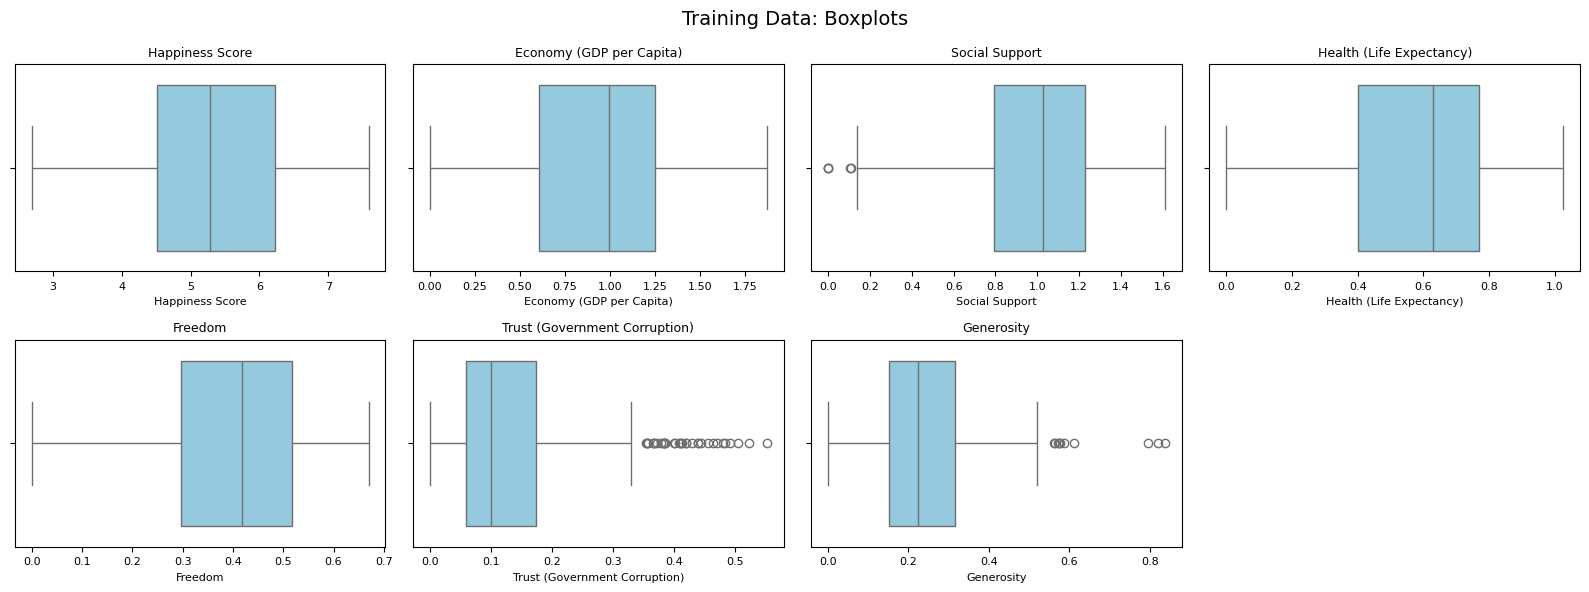

In [229]:
import math
import seaborn as sns

numeric_cols = (
    train_df.select_dtypes(include="number")
    .columns.drop(["Year", "Happiness Rank"], errors="ignore")
)

# Arrange boxplots in two rows
ncols = math.ceil(len(numeric_cols) / 2)

fig, axes = plt.subplots(
    2, ncols,
    figsize=(4 * ncols, 6),
    squeeze=False
)

for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(x=train_df[col], ax=ax, color="skyblue")

    ax.set_title(col, fontsize=9)
    ax.set_xlabel(col, fontsize=8)
    ax.set_ylabel("")
    ax.tick_params(labelsize=8)

# Hide unused subplots
for ax in list(axes.flat)[len(numeric_cols):]:
    ax.set_visible(False)

fig.suptitle("Training Data: Boxplots", fontsize=14)
plt.tight_layout()
plt.show()

In [230]:
# Potential Outliers : Outside Q1 ~ Q3 range
for col in numeric_cols:
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flagged = train_df.loc[
        (train_df[col] < lower) | (train_df[col] > upper),
        ["Country", "Year", col]
    ]

    print(f"\n{col}: {len(flagged)} potential outliers")
    display(flagged.sort_values(col))


Happiness Score: 0 potential outliers


,Country,Year,Happiness Score



Economy (GDP per Capita): 0 potential outliers


,Country,Year,Economy (GDP per Capita)



Social Support: 5 potential outliers


,Country,Year,Social Support
147,Central African Republic,2015,0.00000
312,Togo,2016,0.00000
469,Central African Republic,2017,0.00000
310,Benin,2016,0.10419
311,Afghanistan,2016,0.11037


... (4 outputs left out)


Trust (Government Corruption): 35 potential outliers


,Country,Year,Trust (Government Corruption)
177,Luxembourg,2016,0.353290
185,United Arab Emirates,2016,0.355610
9,Australia,2015,0.356370
161,Norway,2016,0.357760
3,Norway,2015,0.365030
318,Switzerland,2017,0.367007
254,Somaliland Region,2016,0.367940
71,Hong Kong,2015,0.371240
16,Luxembourg,2015,0.377980
319,Finland,2017,0.382612



Generosity: 10 potential outliers


,Country,Year,Generosity
187,Malta,2016,0.562370
236,Indonesia,2016,0.565210
346,Thailand,2017,0.572123
341,Malta,2017,0.574731
33,Thailand,2015,0.576300
190,Thailand,2016,0.586960
395,Indonesia,2017,0.611705
128,Myanmar,2015,0.795880
276,Myanmar,2016,0.819710
428,Myanmar,2017,0.838075


From Boxplot, these are potential outliers.
- Social Support
- Trust
- Generosity

Let's check this result with another plot too.

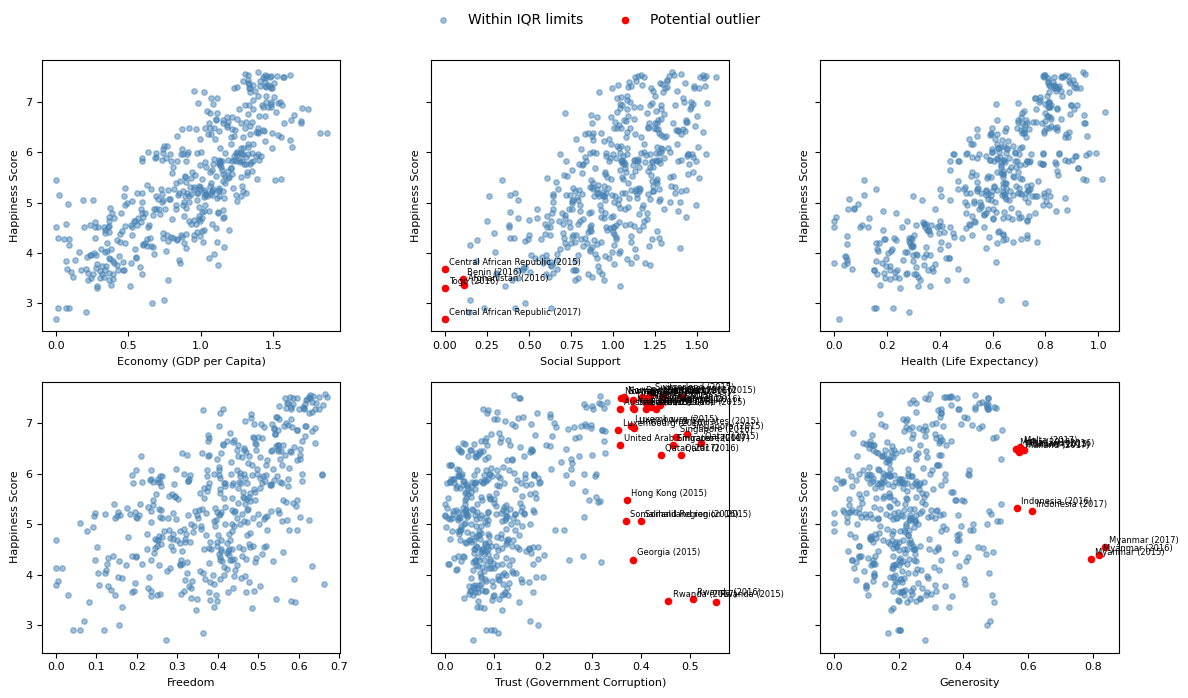

In [231]:
target = "Happiness Score"
features = [col for col in numeric_cols if col != target]

ncols = math.ceil(len(features) / 2)

fig, axes = plt.subplots(
    2, ncols,
    figsize=(4 * ncols, 7),
    sharey=True,
    squeeze=False
)

for ax, col in zip(axes.flat, features):
    q1 = train_df[col].quantile(0.25)
    q3 = train_df[col].quantile(0.75)
    iqr = q3 - q1

    flagged = (
        (train_df[col] < q1 - 1.5 * iqr)
        | (train_df[col] > q3 + 1.5 * iqr)
    )

    ax.scatter(
        train_df.loc[~flagged, col],
        train_df.loc[~flagged, target],
        color="steelblue",
        alpha=0.5,
        s=15,
        label="Within IQR limits"
    )

    ax.scatter(
        train_df.loc[flagged, col],
        train_df.loc[flagged, target],
        color="red",
        s=20,
        label="Potential outlier"
    )

    for _, row in train_df.loc[flagged].iterrows():
        ax.annotate(
            f"{row['Country']} ({int(row['Year'])})",
            (row[col], row[target]),
            xytext=(3, 3),
            textcoords="offset points",
            fontsize=6
        )

    ax.set_xlabel(col, fontsize=8)
    ax.set_ylabel(target, fontsize=8)
    ax.tick_params(labelsize=8)

# Hide unused subplots
for ax in list(axes.flat)[len(features):]:
    ax.set_visible(False)

# Shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center",
    ncol=2,
    frameon=False
)

fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### Encoding : Region
- Use one-hot encoding for Region.
- The new region columns contain 0 or 1

In [232]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore",
)

# Apply encoder for training data only
encoder.fit(train_df[["Region"]])

# Keep the original splits and create encoded splits
encoded_splits = []

for data in [train_df, val_df, test_df]:
  region_encoded = pd.DataFrame(
      encoder.transform(data[["Region"]]),
      columns=encoder.get_feature_names_out(["Region"]),
      index=data.index
  )

  encoded_data = pd.concat(
      [data.drop(columns=["Region"]), region_encoded],
      axis=1
  )

  encoded_splits.append(encoded_data)

train_encoded, val_encoded, test_encoded = encoded_splits
display(train_encoded.head())


,Country,Happiness Score,Economy (GDP per Capita),Social Support,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Year,Region_Australia and New Zealand,Region_Central and Eastern Europe,Region_Eastern Asia,Region_Latin America and Caribbean,Region_Middle East and Northern Africa,Region_North America,Region_Southeastern Asia,Region_Southern Asia,Region_Sub-Saharan Africa,Region_Western Europe
0,Switzerland,7.587,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2015,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,Iceland,7.561,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2015,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,Denmark,7.527,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2015,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,Norway,7.522,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699,2015,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,Canada,7.427,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811,2015,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


# **Standardization**
1. Separate predictors from the target
2. Standardize the numerical predictors. Since target range doesn't need to match the predictors' range, leave the target unscaled.

Scaling is mainly for Ridge, Lasso, and KNN

In [233]:
from sklearn.preprocessing import StandardScaler

target = "Happiness Score"

# Exclude target, not numerical datas (Country), and Year
exclude = [target, "Country", "Year"]

# Standardization targets
X_train = train_encoded.drop(columns=exclude, errors="ignore").copy()
X_val = val_encoded.drop(columns=exclude, errors="ignore").copy()
X_test = test_encoded.drop(columns=exclude, errors="ignore").copy()

y_train = train_encoded[target].copy()
y_val = val_encoded[target].copy()
y_test = test_encoded[target].copy()

# Scale numerical predictors and leave region indicators as one-hot-encoded
numeric_cols = [
    col for col in X_train.columns
    if not col.startswith("Region_")
]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

# Only numerical columns are standardized
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_val_scaled[numeric_cols] = scaler.transform(X_val[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

display(X_train_scaled.head())

,Economy (GDP per Capita),Social Support,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Region_Australia and New Zealand,Region_Central and Eastern Europe,Region_Eastern Asia,Region_Latin America and Caribbean,Region_Middle East and Northern Africa,Region_North America,Region_Southeastern Asia,Region_Southern Asia,Region_Sub-Saharan Africa,Region_Western Europe
0,1.128964,1.128139,1.506687,1.749332,2.562987,0.415050,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.902078,1.293734,1.533406,1.504319,0.059897,1.476821,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.957866,1.162910,1.228285,1.641540,3.136666,0.754540,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1.279491,1.069842,1.272344,1.777030,2.070607,0.797157,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.959817,1.043646,1.357461,1.532282,1.751706,1.642799,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


# Understand the data
Plots to understand the data and read the trend and relationship between features.

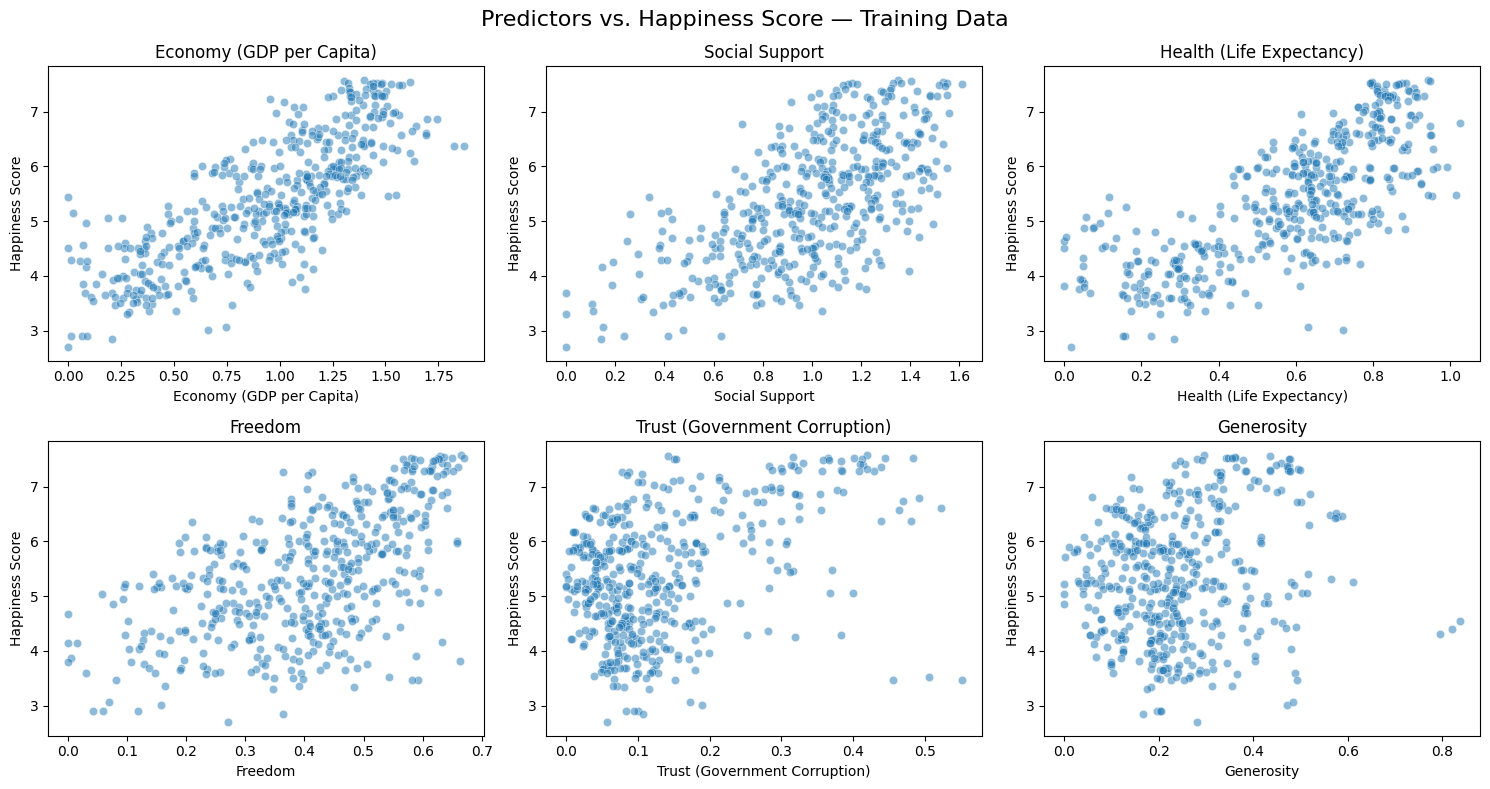

In [234]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

ncols = 3
nrows = math.ceil(len(numeric_cols) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(15, 4 * nrows),
    squeeze=False
)

for ax, col in zip(axes.flat, numeric_cols):
    sns.scatterplot(
        x=X_train[col],
        y=y_train,
        alpha=0.5,
        ax=ax
    )

    ax.set_xlabel(col)
    ax.set_ylabel("Happiness Score")
    ax.set_title(col)

# Hide unused subplots
for ax in list(axes.flat)[len(numeric_cols):]:
    ax.set_visible(False)

fig.suptitle("Predictors vs. Happiness Score — Training Data", fontsize=16)
plt.tight_layout()
plt.show()

From the plot, Economy, Social Support, Health(Life Expectancy), Freedom shows  similarly and linearly positive relations with Happiness score.

On the other hands, Trust and Generosity don't seem have linear pattern between Happiness Scorea and the feature. They are gathered in the left side.

 # **Evaluation**

 Which performance metrics will you
use? Evaluated on what part of the dataset?


- Primary metric: RMSE, in happiness-score points.


- Supporting metrics: MAE and \(R^2\).


- Training: 2015–2017.

- Validation: 2018 for model/hyperparameter selection.

- Test: 2019 for final evaluation only.

In [235]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Predict the mean for every observation
training_mean = y_train.mean()
baseline = np.full(len(y_val), training_mean) # [mean, mean, .... ]

# Evaluate on validation data
baseline_mae = mean_absolute_error(y_val, baseline)
baseline_mse = mean_squared_error(y_val, baseline)
baseline_rmse = np.sqrt(mse)
baseline_r2 = r2_score(y_val, baseline)

print(f"Baseline MAE: {baseline_mae:.5f}")
print(f"Baseline MSE: {baseline_mse:.5f}")
print(f"Baseline RMSE: {baseline_rmse:.5f}")
print(f"Baseline R^2: {baseline_r2:.5f}")

Baseline MAE: 0.92660
Baseline MSE: 1.24529
Baseline RMSE: 1.11592
Baseline R^2: -0.00002


- RMSE / MAE are lower is better.
- R ^2 is higher is better.

Our models should aim for lower validation MAE/RMSE and higher R^ than this baseline

# Model

- Linear Regression

- Polynomial Regression :Interactions

- Ridge : one-standard-error rule to choose the largest lambda

- Lasso : one-standard-error rule to choose the largest lambda

- KNN

In [236]:
selected_models = {}
validation_results = []

## 1. Linear Regression
- For Linear Regression, we can use unscaled data since coefficients can adjust to feeature scales.

In [237]:
from sklearn.linear_model import LinearRegression

# Train the model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict validation scores
linear_predictions = linear_model.predict(X_val)

# Evaluate
linear_mae = mean_absolute_error(y_val, linear_predictions)
linear_mse = mean_squared_error(y_val, linear_predictions)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_val, linear_predictions)

print(f"Linear Regression MAE: {linear_mae:.5f}")
print(f"Linear Regression RMSE: {linear_rmse:.5f}")
print(f"Linear Regression R²: {linear_r2:.5f}")

Linear Regression MAE: 0.36873
Linear Regression RMSE: 0.47476
Linear Regression R²: 0.81899


In [238]:
# Compare with the baseline(mean)
comparison = pd.DataFrame({
    "Model" : ["Mean baseline", "Linear regression"],
    "MAE" : [baseline_mae, linear_mae],
    "RMSE" : [baseline_rmse, linear_rmse],
    "R^2" : [baseline_r2, linear_r2]
})

comparison.set_index("Model", inplace=True)
display(comparison)

,MAE,RMSE,R^2
Model,,,
Mean baseline,0.926596,1.115924,-0.000022
Linear regression,0.368734,0.474764,0.818993


In [239]:
# Inspect the coefficients of the linear model
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": linear_model.coef_,
})

display(coefficients)
print(f"Intercept: {linear_model.intercept_:.3f}")

,Feature,Coefficient
0,Economy (GDP per Capita),1.022727
1,Social Support,0.535035
2,Health (Life Expectancy),0.701512
3,Freedom,1.216584
4,Trust (Government Corruption),1.011329
5,Generosity,0.423438
6,Region_Australia and New Zealand,0.428417
7,Region_Central and Eastern Europe,-0.110524
8,Region_Eastern Asia,-0.377365
9,Region_Latin America and Caribbean,0.469647


Intercept: 2.831


### **Linear Regression Result**

- **RMSE** : 1.116 -> 0.474 : Decreased
- **R^2** : -0.000022 -> 0.819 : Increased

Linear regression model shows better performance than the baseline.





- **Indicator coefficient magnitude order**:  
  - Freedom > Economy > Trust > Health > Social Support > Generosity  

- **Interpretation**: A one-unit increase in each predictor is associated with **a change of coefficient happiness-score points.**
  - Holding other predictors fixed.



## 2. Polynomial Regression

,Degree,MAE,RMSE,R²
0,1,0.368734,0.474764,0.818993
1,2,0.372185,0.465466,0.826014
2,3,0.343030,0.435453,0.847727
3,4,0.555898,0.895131,0.356553
4,5,48.878304,198.518103,-31646.572002


Selected degree: 3


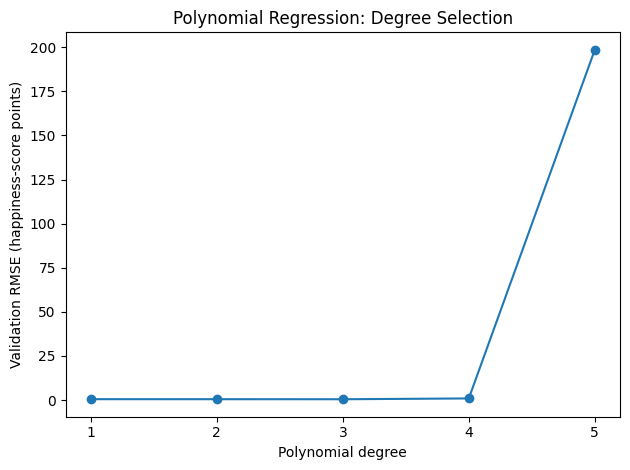

In [240]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

numeric_cols = [
    col for col in X_train.columns
    if not col.startswith("Region_")
]

# Shared evaluation function
def evaluate(model, X, y):
    predictions = model.predict(X)
    return {
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R²": r2_score(y, predictions),
    }

poly_models = {}
poly_results = []

for degree in [1, 2, 3, 4, 5]:
    preprocessing = ColumnTransformer(
        transformers=[
            ("polynomial", Pipeline([
                ("expand", PolynomialFeatures(
                    degree=degree,
                    include_bias=False
                )),
                ("scale", StandardScaler()),
            ]), numeric_cols),
        ],
        remainder="passthrough"
    )

    model = Pipeline([
        ("preprocessing", preprocessing),
        ("regression", LinearRegression()),
    ])

    model.fit(X_train, y_train)
    poly_models[degree] = model

    poly_results.append({
        "Degree": degree,
        **evaluate(model, X_val, y_val)
    })

poly_results = pd.DataFrame(poly_results)
display(poly_results)

best_degree = int(
    poly_results.loc[poly_results["RMSE"].idxmin(), "Degree"]
)
best_poly = poly_models[best_degree]

# Save validation result
validation_results.append({
    "Model": "Polynomial",
    "Parameter": best_degree,
    **evaluate(best_poly, X_val, y_val)
})

print("Selected degree:", best_degree)

plt.plot(poly_results["Degree"], poly_results["RMSE"], marker="o")
plt.xticks(poly_results["Degree"])
plt.xlabel("Polynomial degree")
plt.ylabel("Validation RMSE (happiness-score points)")
plt.title("Polynomial Regression: Degree Selection")
plt.tight_layout()
plt.show()

From the result, RMSE exponentially increased after degree 4.
Degree 3 has the lowest RMSE.

## **k-fold CV**
- Since our data is chronological data, we are going to use expanding-window cross-validation rather than shuffled k-fold.
- We can also use shuffled k-fold, however, the same country's observations across years may be similar, it could hint the answer. **To prevent data leakage,** we are using expanding-window CV.


| Fold | Training years | Validation year |
|---|---|---|
| 1 | 2015 | 2016 |
| 2 | 2015–2016 | 2017 |

In [241]:
# Match the row order of X_train
years = train_encoded.loc[X_train.index, "Year"].to_numpy()

# 2 folds
cv_folds = [
    (
        np.flatnonzero(years < validation_year),
        np.flatnonzero(years == validation_year)
    )
    for validation_year in [2016, 2017]
]

def scaled_pipeline(estimator):
    preprocessing = ColumnTransformer(
        [("numeric", StandardScaler(), numeric_cols)],
        remainder="passthrough"
    )

    return Pipeline([
        ("preprocessing", preprocessing),
        ("model", estimator),
    ])

## **Ridge & Lasso with CV**
- Choose alpha using one-standard error rule
- threshold = minimum mean CV RMSE + SE at the miminum

Ridge: selected alpha = 49.5354


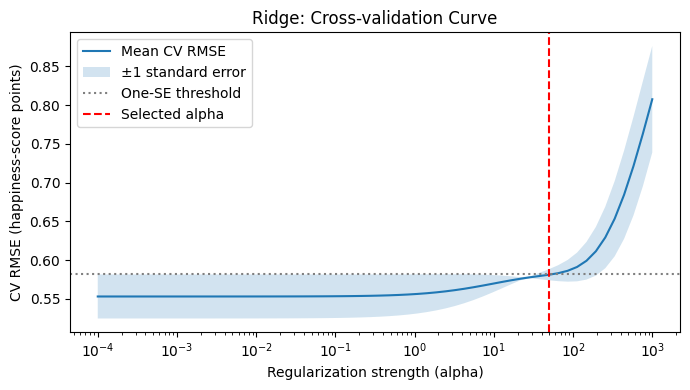

Lasso: selected alpha = 0.0179571


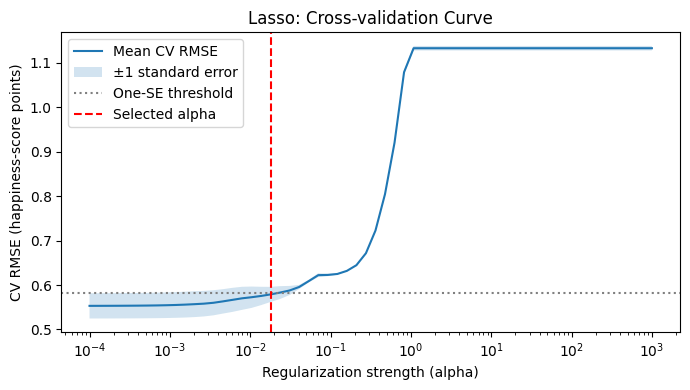

In [242]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

alphas = np.logspace(-4, 3, 60)

for name, estimator in [
    ("Ridge", Ridge()),
    ("Lasso", Lasso(max_iter=100000)),
]:
    search = GridSearchCV(
        estimator=scaled_pipeline(estimator),
        param_grid={"model__alpha": alphas},
        scoring="neg_root_mean_squared_error",
        cv=cv_folds,
        refit=False,
        error_score="raise"
    )

    search.fit(X_train, y_train)

    results = search.cv_results_
    alpha_values = np.array(
        results["param_model__alpha"], dtype=float
    )
    mean_rmse = -results["mean_test_score"]

    # Sample standard deviation across folds / sqrt(number of folds)
    fold_errors = np.vstack([
        -results[f"split{i}_test_score"]
        for i in range(len(cv_folds))
    ])
    se_rmse = fold_errors.std(axis=0, ddof=1) / np.sqrt(len(cv_folds))

    minimum_index = np.argmin(mean_rmse)
    threshold = mean_rmse[minimum_index] + se_rmse[minimum_index]

    eligible = np.flatnonzero(mean_rmse <= threshold)
    selected_index = eligible[np.argmax(alpha_values[eligible])]
    selected_alpha = alpha_values[selected_index]

    # Refit using all training years
    selected = scaled_pipeline(estimator)
    selected.set_params(model__alpha=selected_alpha)
    selected.fit(X_train, y_train)


    # Save validation results
    selected_models[name] = selected
    validation_results.append({
        "Model": name,
        "Parameter": selected_alpha,
        **evaluate(selected, X_val, y_val)
    })

    print(f"{name}: selected alpha = {selected_alpha:.6g}")


    # One standard error area
    plt.figure(figsize=(7, 4))
    plt.semilogx(alpha_values, mean_rmse, label="Mean CV RMSE")
    plt.fill_between(
        alpha_values,
        mean_rmse - se_rmse,
        mean_rmse + se_rmse,
        alpha=0.2,
        label="±1 standard error"
    )

    # Threshold
    plt.axhline(
        threshold, color="gray", linestyle=":",
        label="One-SE threshold"
    )


    plt.axvline(
        selected_alpha, color="red", linestyle="--",
        label="Selected alpha"
    )
    plt.xlabel("Regularization strength (alpha)")
    plt.ylabel("CV RMSE (happiness-score points)")
    plt.title(f"{name}: Cross-validation Curve")
    plt.legend()
    plt.tight_layout()
    plt.show()

Unlike Ridge, Lasso drops features.

In [243]:
# Observe which feature Lasso drops
lasso = selected_models["Lasso"]

feature_names = (lasso.named_steps["preprocessing"].get_feature_names_out())

lasso_coefficients = pd.DataFrame({
    "Feature" : feature_names,
    "Coefficient" : lasso.named_steps["model"].coef_
})
display(lasso_coefficients)

dropped = lasso_coefficients.loc[lasso_coefficients["Coefficient"].eq(0), "Feature"].tolist()

print("Features dropped by Lasso:", dropped)

,Feature,Coefficient
0,numeric__Economy (GDP per Capita),0.446879
1,numeric__Social Support,0.189254
2,numeric__Health (Life Expectancy),0.257937
3,numeric__Freedom,0.183901
4,numeric__Trust (Government Corruption),0.116707
5,numeric__Generosity,0.055570
6,remainder__Region_Australia and New Zealand,0.000000
7,remainder__Region_Central and Eastern Europe,0.000000
8,remainder__Region_Eastern Asia,-0.000000
9,remainder__Region_Latin America and Caribbean,0.465765


Features dropped by Lasso: ['remainder__Region_Australia and New Zealand', 'remainder__Region_Central and Eastern Europe', 'remainder__Region_Eastern Asia', 'remainder__Region_Middle East and Northern Africa', 'remainder__Region_North America', 'remainder__Region_Southeastern Asia', 'remainder__Region_Southern Asia', 'remainder__Region_Sub-Saharan Africa']


Lasso only drops "encoded region" features (coefficient = 0)

## **KNN + CV**
- Select k
- Use the same CV folds

In [244]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV

# Select the best k
knn_search = GridSearchCV(
    estimator=scaled_pipeline(KNeighborsRegressor()),
    param_grid={"model__n_neighbors": list(range(1, 32, 2))},
    scoring="neg_root_mean_squared_error",
    cv=cv_folds,
    refit=True,
    error_score="raise"
)

knn_search.fit(X_train, y_train)
best_knn = knn_search.best_estimator_

print("Selected k:", knn_search.best_params_["model__n_neighbors"])

Selected k: 1


K=1 may have the lowest RMSE, however, it overfits.

Apply one-standard-error rule to KNN too.

In [247]:
results = knn_search.cv_results_

k_values = np.array(
    results["param_model__n_neighbors"], dtype=int
)
mean_rmse = -results["mean_test_score"]

# Standard error across CV folds
n_folds = knn_search.n_splits_

fold_errors = np.vstack([
    -results[f"split{i}_test_score"]
    for i in range(n_folds)
])

se_rmse = fold_errors.std(axis=0, ddof=1) / np.sqrt(n_folds)

# Sort by k for plotting
order = np.argsort(k_values)
k_values = k_values[order]
mean_rmse = mean_rmse[order]
se_rmse = se_rmse[order]

# One-SE rule: largest k within the threshold
minimum_index = np.argmin(mean_rmse)
threshold = mean_rmse[minimum_index] + se_rmse[minimum_index]
selected_k = k_values[mean_rmse <= threshold].max()

# Define best knn with new k
best_knn = clone(knn_search.estimator)
best_knn.set_params(model__n_neighbors=int(selected_k))
best_knn.fit(X_train, y_train)


# Save validation result
validation_results.append({
    "Model": "KNN",
    "Parameter": selected_k,
    **evaluate(best_knn, X_val, y_val)
})

Plot the curve to find the best k using one standard error rule

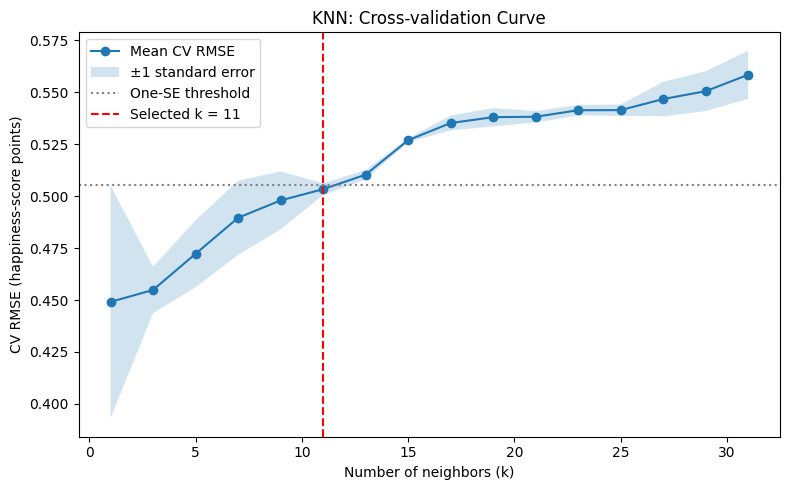

Selected k: 11


In [248]:
# Plot curve and shaded area
plt.figure(figsize=(8, 5))

plt.plot(k_values, mean_rmse, marker="o", label="Mean CV RMSE")

plt.fill_between(
    k_values,
    mean_rmse - se_rmse,
    mean_rmse + se_rmse,
    alpha=0.2,
    label="±1 standard error"
)

plt.axhline(
    threshold, color="gray", linestyle=":",
    label="One-SE threshold"
)

plt.axvline(
    selected_k, color="red", linestyle="--",
    label=f"Selected k = {selected_k}"
)

plt.xlabel("Number of neighbors (k)")
plt.ylabel("CV RMSE (happiness-score points)")
plt.title("KNN: Cross-validation Curve")
plt.legend()
plt.tight_layout()
plt.show()

print("Selected k:", selected_k)

### **Compare validation performace across all models**

In [249]:
display(
    pd.DataFrame(validation_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

,Model,Parameter,MAE,RMSE,R²
0,Polynomial,3.000000,0.343030,0.435453,0.847727
1,KNN,11.000000,0.364726,0.471780,0.821261
2,Lasso,0.017957,0.392114,0.504709,0.795440
3,Ridge,49.535352,0.392095,0.504745,0.795410


According to the result, KNN shows the lowest RMSE, MAE and highest R^2 with K=11.
Therefore, among 4 models, KNN is the best model, therefore I would choose this model for prediction.

Best k: Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('numeric', StandardScaler(),
                                                  ['Economy (GDP per Capita)',
                                                   'Social Support',
                                                   'Health (Life Expectancy)',
                                                   'Freedom',
                                                   'Trust (Government '
                                                   'Corruption)',
                                                   'Generosity'])])),
                ('model', KNeighborsRegressor(n_neighbors=11))])


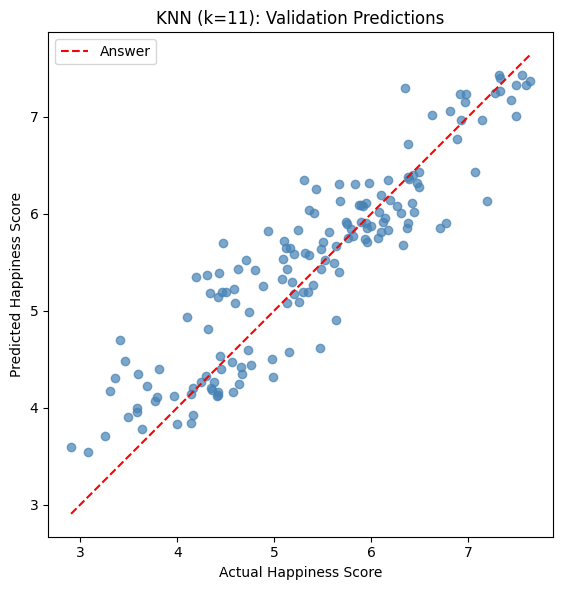

In [250]:
# KNN with k=11
print("Best k:", best_knn)

# The pipeline handles scaling
knn_predictions = best_knn.predict(X_val)

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(y_val, knn_predictions, alpha=0.7, color="steelblue")

# Perfect-prediction reference line
lower = min(y_val.min(), knn_predictions.min())
upper = max(y_val.max(), knn_predictions.max())

ax.plot(
    [lower, upper], [lower, upper],
    "r--", label="Answer"
)

ax.set(
    title="KNN (k=11): Validation Predictions",
    xlabel="Actual Happiness Score",
    ylabel="Predicted Happiness Score"
)
ax.set_aspect("equal", adjustable="box")
ax.legend()

plt.tight_layout()
plt.show()

As we can see from the plot, KNN shows highly accurate prediction results.

# **Choose the final model and refit**

- I chose the final model as KNN with K=11.
- Refit with both training and validation datasets

In [251]:
from sklearn.base import clone
# KNN with k=11
chosen_model = clone(knn_search.estimator)
chosen_model.set_params(model__n_neighbors=11)
model_name = "KNN"

# Combine training and validation data
X_development = pd.concat([X_train, X_val], axis=0)
y_development = pd.concat([y_train, y_val], axis=0)

# Fitting the pipeline also refits its scaling on development data.
final_model = clone(chosen_model)
final_model.fit(X_development, y_development)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('numeric', StandardScaler(),
                                                  ['Economy (GDP per Capita)',
                                                   'Social Support',
                                                   'Health (Life Expectancy)',
                                                   'Freedom',
                                                   'Trust (Government '
                                                   'Corruption)',
                                                   'Generosity'])])),
                ('model', KNeighborsRegressor(n_neighbors=11))])

# **Evaluate the final model on the test set**

In [252]:
from sklearn.dummy import DummyRegressor

# Final model predictions
test_predictions = final_model.predict(X_test)

# Baseline uses the combined development target mean
final_baseline = DummyRegressor(strategy="mean")
final_baseline.fit(X_development, y_development)
baseline_test_predictions = final_baseline.predict(X_test)

def calculate_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted),
    }

test_results = pd.DataFrame([
    {
        "Model": "baseline",
        **calculate_metrics(y_test, baseline_test_predictions)
    },
    {
        "Model": model_name,
        **calculate_metrics(y_test, test_predictions)
    }
])


display(test_results.round(3))

,Model,MAE,RMSE,R²
0,baseline,0.916,1.110,-0.001
1,KNN,0.358,0.443,0.841


Plot predicted values and residuals

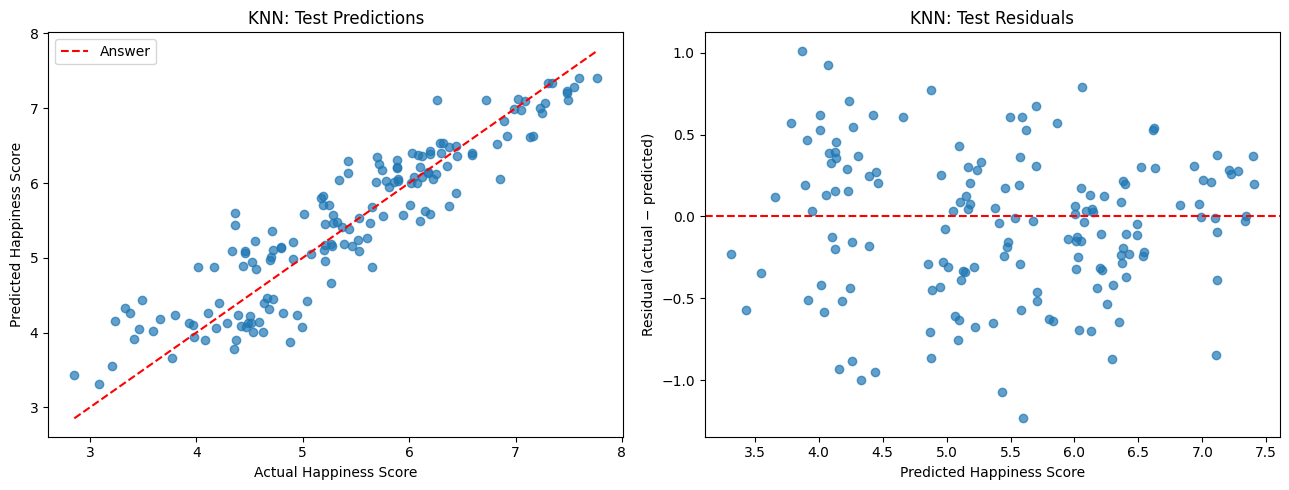

In [253]:
residuals = np.asarray(y_test) - test_predictions

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual vs. predicted
axes[0].scatter(y_test, test_predictions, alpha=0.7)

lower = min(np.min(y_test), np.min(test_predictions))
upper = max(np.max(y_test), np.max(test_predictions))

axes[0].plot(
    [lower, upper], [lower, upper],
    "r--", label="Answer"
)
axes[0].set(
    xlabel="Actual Happiness Score",
    ylabel="Predicted Happiness Score",
    title=f"{model_name}: Test Predictions"
)
axes[0].legend()

# Residuals vs. predictions
axes[1].scatter(test_predictions, residuals, alpha=0.7)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(
    xlabel="Predicted Happiness Score",
    ylabel="Residual (actual − predicted)",
    title=f"{model_name}: Test Residuals"
)

plt.tight_layout()
plt.show()

Lastly, to compare with training error, refit final model with training dataset.


In [254]:
training_predictions = final_model.predict(X_development)

training_mae = mean_absolute_error(y_development, training_predictions)
training_rmse = np.sqrt(
    mean_squared_error(y_development, training_predictions)
)
training_r2 = r2_score(y_development, training_predictions)


for name, X, y in [
    ("Training (2015–2018)", X_development, y_development),
    ("Test (2019)", X_test, y_test),
]:
    predictions = final_model.predict(X)

    print(f"\n{name}")
    print(f"MAE: {mean_absolute_error(y, predictions):.3f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(y, predictions)):.3f}")
    print(f"R²: {r2_score(y, predictions):.3f}")


Training (2015–2018)
MAE: 0.325
RMSE: 0.418
R²: 0.863

Test (2019)
MAE: 0.358
RMSE: 0.443
R²: 0.841


- **Test Predictions**:
  - most points follow the diagonal. The lowest actual scores tend to be overpredicted, while the highest tend to be slightly underpredicted—consistent with KNN averaging neighboring scores.

- **Test Residuals** :
  - residuals occur on both sides of zero. Several errors approach or exceed one happiness-score point(+-1<), and the spread appears smaller at high predicted scores.

- **Test Evaluation result**
  - RMSE increases by 0.049 points, and \(R^2\) decreases by 0.034. The model still performs well on the held-out 2019 data.
| Metric | Validation | Test |
|---|---:|---:|
| MAE ↓ | 0.271 | 0.358 |
| RMSE ↓ | 0.394 | 0.443 |
| \(R^2\) ↑ | 0.875 | 0.841 |

- **Compare with training error**
| Metric | Training | Test |
|---|---:|---:|
| MAE | 0.325 | 0.358 |
| RMSE | 0.418 | 0.443 |
| \(R^2\) | 0.863 | 0.841 |

KNN with K=11 achieved similar performance on training and test datsets, with RMSE increasing 0.394 to 0.443 and (R^2) decreasing from 0.875 to 0.841.
This small gap suggests the model does not overfitting on the 2019 data.

# Conclusion.

Based on the results, our selected **KNN model with \(k=11\)** predicted happiness scores well on the held-out 2019 data, achieving an RMSE of 0.443, MAE of 0.358, and \(R^2\) of 0.841.

These results support our prediction question: **“How accurately can socioeconomic indicators predict a country’s happiness score in a later report year?”** This assumes that the later year’s predictor values are available.


However, evaluation on one new test year does not give reliability for future years data.


Our results do not fully answer the broader question : **"Which indicators are most strongly associated with national happiness?"**

KNN does not directly provide coefficients, and strong predictive performance does not establish individual feature importance.

They do not identify which individual indicators have the strongest relationships with happiness.


 ***Correlation analysis with confidence interval*** would help investigate this question.